# University Intent Router with ModernBERT

This notebook builds a small intent router for a university assistant. It reads a user query and decides which route should handle it, along with a confidence percentage for each route.

## Routes
| Label | Meaning |
|---|---|
| general_info | Questions about fees, admissions, programs, timings, location |
| booking | Requests to book a campus visit, counselor meeting or appointment |
| media_link | Requests for university images, photos or videos |
| oos | Anything outside these three routes |

## Objectives
- Define routes clearly through a system prompt
- Build train, validation and test datasets
- Train a simple baseline and fine-tune ModernBERT
- Check overfitting and underfitting with learning curves
- Evaluate with precision, recall, F1 and confusion matrix
- Compare both models and analyze errors

## Table of Contents
1. Setup and Initialization
2. System Prompt
3. Dataset Creation
4. Dataset Exploration
5. Baseline Model
6. Fine-Tuning ModernBERT
7. Model Performance Evaluation
8. Inference
9. Save Model

## Step 1 | Setup and Initialization

Import the libraries, fix the random seed for reproducible results, and set the main configuration values used across the notebook.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import re
import random
import itertools
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax
from datasets import Dataset, DatasetDict, load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)

SEED = 42
MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LEN = 64
OUTPUT_DIR = "/kaggle/working/university_router"

LABEL_NAMES = ["general_info", "booking", "media_link", "oos"]
LABEL2ID = {name: i for i, name in enumerate(LABEL_NAMES)}
ID2LABEL = {i: name for name, i in LABEL2ID.items()}
OOS_ID = LABEL2ID["oos"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_style("whitegrid")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("Labels:", LABEL2ID)

GPU: Tesla T4
Labels: {'general_info': 0, 'booking': 1, 'media_link': 2, 'oos': 3}


## Step 2 | System Prompt

The system prompt defines each route in one place: its meaning, its scope and a wide set of example queries in English and Roman Urdu. These examples are the seed data, and the next step expands them into a full training dataset.

In [2]:
ROUTES = {
    "general_info": {
        "description": "The user wants information about the university, such as fees, admissions, programs, eligibility, scholarships, hostel, transport, timings, faculty, results or location.",
        "examples": [
            "what is the fee for bs computer science",
            "when do admissions open",
            "what is the last date to apply",
            "is there a hostel for girls",
            "what programs do you offer",
            "what is the eligibility for mbbs",
            "do you offer scholarships",
            "what are the university timings",
            "where is the main campus located",
            "is transport available for students",
            "what documents are required for admission",
            "how much is the hostel fee per month",
            "is there an entry test for engineering",
            "what is the merit for bs software engineering",
            "do you have evening classes",
            "can i pay the fee in installments",
            "what is the duration of the mba program",
            "is the degree hec recognized",
            "when will the merit list be announced",
            "what is the contact number of the admission office",
            "bs cs ki fee kitni hai",
            "admission kab open honge",
            "hostel ki fees kya hai",
            "scholarship milti hai kya",
            "university kahan hai",
            "kon kon se programs hain",
            "entry test kab hai",
            "merit list kab aayegi",
            "transport ki facility hai",
            "fees?",
        ],
    },
    "booking": {
        "description": "The user wants to book, schedule, reschedule or cancel something, such as a campus visit, counselor meeting, entry test slot, hostel room or appointment.",
        "examples": [
            "i want to book a campus visit",
            "schedule a meeting with an admission counselor",
            "can i reschedule my visit to friday",
            "please cancel my appointment",
            "book an entry test slot for me",
            "i want to visit the campus tomorrow",
            "can i get an appointment with the dean",
            "reserve a hostel room for me",
            "book a seat for the open house",
            "i need a slot for document verification",
            "set up a call with the admission team",
            "can i come for a campus tour on saturday",
            "book a counseling session for next week",
            "i want to change my visit time",
            "register me for the orientation session",
            "is there any slot available on monday for a visit",
            "fix a meeting with the finance office",
            "cancel my campus tour booking",
            "book an interview slot for mba",
            "i want to meet someone from admissions",
            "campus visit book karni hai",
            "counselor se appointment chahiye",
            "kal visit ke liye time de dein",
            "meri booking cancel kar dein",
            "entry test ka slot book karo",
            "hostel room reserve karna hai",
            "visit ka time change karna hai",
            "monday ko aana hai booking kar dein",
            "meeting set kar do admission walon se",
            "book visit",
        ],
    },
    "media_link": {
        "description": "The user wants to see university images, photos or videos, such as campus pictures, hostel photos, lab images, library photos, event pictures or a campus tour video.",
        "examples": [
            "send me campus pictures",
            "show me hostel photos",
            "do you have a campus tour video",
            "can i see pictures of the computer lab",
            "share photos of the library",
            "show me images of the girls hostel",
            "send convocation pictures",
            "i want to see the classrooms",
            "do you have a video of the campus",
            "share images of the sports ground",
            "show me what the cafeteria looks like",
            "send pictures of the boys hostel rooms",
            "can you share event photos",
            "show me the auditorium",
            "share a virtual tour of the university",
            "pictures of the medical college please",
            "send me photos of the engineering labs",
            "i want to see hostel rooms before admission",
            "share the campus gallery",
            "show images of the mosque on campus",
            "hostel ki pictures bhejo",
            "campus ki images dikhao",
            "lab ki photos bhej dein",
            "library ki tasveerein dikhayein",
            "convocation ki photos hain",
            "campus ki video bhejo",
            "hostel ke kamre dikhao",
            "ground ki pics share karo",
            "university ki pictures",
            "pics?",
        ],
    },
    "oos": {
        "description": "The query is not related to the three routes above, such as weather, food orders, banking, travel, shopping, jokes, coding help or general chit chat.",
        "examples": [
            "what is the weather today",
            "order me a pizza",
            "tell me a joke",
            "transfer money to my account",
            "book a flight to dubai",
            "what is the capital of france",
            "play some music",
            "how do i fix my car engine",
            "set an alarm for 6am",
            "who won the cricket match yesterday",
            "recommend a good movie",
            "convert 100 dollars to rupees",
            "write a python function for sorting",
            "what is my bank balance",
            "how to lose weight fast",
            "book a table at a restaurant",
            "what time is it in london",
            "translate hello into french",
            "how do i reset my phone",
            "suggest a recipe for biryani",
            "aaj mausam kaisa hai",
            "pizza order kar do",
            "koi joke sunao",
            "gaana chalao",
            "mera balance kitna hai",
            "dubai ki ticket book karo",
            "car ka engine kaise theek karein",
            "biryani kaise banate hain",
            "hello",
            "ok thanks",
        ],
    },
}

SYSTEM_PROMPT = "You are an intent router for a university assistant. Classify each user query into exactly one route.\n\n"
for name, route in ROUTES.items():
    SYSTEM_PROMPT += f"Route: {name}\nMeaning: {route['description']}\nExamples:\n"
    SYSTEM_PROMPT += "".join(f"- {ex}\n" for ex in route["examples"])
    SYSTEM_PROMPT += "\n"

print(SYSTEM_PROMPT[:1500])
print("...")
print(pd.Series({name: len(r["examples"]) for name, r in ROUTES.items()}, name="seed examples"))

You are an intent router for a university assistant. Classify each user query into exactly one route.

Route: general_info
Meaning: The user wants information about the university, such as fees, admissions, programs, eligibility, scholarships, hostel, transport, timings, faculty, results or location.
Examples:
- what is the fee for bs computer science
- when do admissions open
- what is the last date to apply
- is there a hostel for girls
- what programs do you offer
- what is the eligibility for mbbs
- do you offer scholarships
- what are the university timings
- where is the main campus located
- is transport available for students
- what documents are required for admission
- how much is the hostel fee per month
- is there an entry test for engineering
- what is the merit for bs software engineering
- do you have evening classes
- can i pay the fee in installments
- what is the duration of the mba program
- is the degree hec recognized
- when will the merit list be announced
- what 

## Step 3 | Dataset Creation

There is no ready dataset for these routes, so we build one:
- **Templates with slots** (program, facility, place, day) generate many natural queries per route
- **Seed examples** from the system prompt are added as they are
- **CLINC OOS** queries, plus queries from unrelated CLINC intents, form the `oos` class
- **Typo copies** make the model robust to real user spelling

Each row also gets a `group` id (its template or source), used in the next step to keep similar queries out of both train and test.

In [3]:
PER_TEMPLATE = 80
CLASS_CAP = 1500
TYPO_RATIO = 0.3
CLINC_PER_INTENT = 10

SLOTS = {
    "program": ["bs computer science", "bs software engineering", "bs data science", "mbbs", "bba", "mba",
                "bs physics", "bs english", "pharm d", "llb", "ms computer science", "phd mathematics"],
    "topic": ["fee", "merit", "eligibility", "duration", "seats", "entry test"],
    "facility": ["hostel", "transport", "library", "cafeteria", "sports complex", "medical center", "wifi", "mosque"],
    "item": ["campus visit", "campus tour", "counselor meeting", "entry test slot", "hostel room", "interview slot",
             "document verification slot", "open house seat", "orientation session", "appointment with the dean"],
    "day": ["today", "tomorrow", "monday", "friday", "saturday", "next week", "this weekend", "kal", "parson"],
    "place": ["campus", "hostel", "girls hostel", "boys hostel", "library", "computer lab", "physics lab", "cafeteria",
              "auditorium", "sports ground", "mosque", "classrooms", "medical college", "main gate"],
    "media": ["pictures", "photos", "images", "video", "pics", "gallery"],
    "thing": ["pizza", "burger", "biryani", "cab", "movie ticket", "train ticket"],
}

TEMPLATES = {
    "general_info": [
        "what is the {topic} for {program}",
        "tell me the {topic} of {program}",
        "{program} {topic}",
        "{program} ki {topic} kya hai",
        "how much is the fee for {program}",
        "{program} ki fee kitni hai",
        "do you offer {program}",
        "kya {program} available hai",
        "what is the last date to apply for {program}",
        "{program} mein admission kab hain",
        "is there a {facility} on campus",
        "tell me about the {facility}",
        "{facility} ki facility hai",
        "what are the {facility} timings",
        "{facility} ke baare mein batayein",
    ],
    "booking": [
        "i want to book a {item}",
        "book a {item} for {day}",
        "can i book a {item} on {day}",
        "please schedule a {item} for {day}",
        "reschedule my {item} to {day}",
        "cancel my {item}",
        "{day} ke liye {item} book kar dein",
        "{item} book karni hai",
        "mujhe {day} {item} chahiye",
        "is a {item} available {day}",
        "{item} ka time change karna hai",
        "reserve a {item} for me",
    ],
    "media_link": [
        "send me {place} {media}",
        "show me {media} of the {place}",
        "can i see {media} of the {place}",
        "share {place} {media}",
        "do you have {media} of the {place}",
        "i want to see the {place}",
        "{place} ki {media} bhejo",
        "{place} ki {media} dikhao",
        "{place} ki {media} share karo",
        "{place} {media}?",
        "{place} kaisa dikhta hai",
        "what does the {place} look like",
    ],
    "oos": [
        "{thing} order kar do",
        "order a {thing} for me",
        "mujhe {thing} chahiye",
        "{thing} kitne ka hai",
    ],
}

EXCLUDED_CLINC = {
    "schedule_meeting", "meeting_schedule", "cancel_reservation", "confirm_reservation",
    "accept_reservations", "cancel", "reminder", "reminder_update", "calendar", "calendar_update",
}

ROWS = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]


def expand(template, r):
    keys = re.findall(r"\{(\w+)\}", template)
    combos = list(itertools.product(*(SLOTS[k] for k in keys)))
    r.shuffle(combos)
    return [template.format(**dict(zip(keys, c))) for c in combos[:PER_TEMPLATE]]


def neighbors(c):
    for row in ROWS:
        i = row.find(c)
        if i >= 0:
            return [row[j] for j in (i - 1, i + 1) if 0 <= j < len(row)]
    return []


def typo_word(w, r):
    i = r.randrange(1, len(w) - 1)
    op = r.choice(["swap", "delete", "double", "neighbor"])
    if op == "swap":
        return w[:i] + w[i + 1] + w[i] + w[i + 2:]
    if op == "delete":
        return w[:i] + w[i + 1:]
    if op == "double":
        return w[:i] + w[i] + w[i:]
    near = neighbors(w[i].lower())
    return w[:i] + r.choice(near) + w[i + 1:] if near else w


def add_typos(text, r, max_typos=2):
    words = text.split()
    idx = [i for i, w in enumerate(words) if len(w) >= 4 and w.isalpha()]
    if not idx:
        return text
    for i in r.sample(idx, min(len(idx), r.randint(1, max_typos))):
        words[i] = typo_word(words[i], r)
    return " ".join(words)


rng = random.Random(SEED)
rows = []

for label, templates in TEMPLATES.items():
    for t_id, template in enumerate(templates):
        rows += [{"text": text, "label": label, "group": f"{label}_t{t_id}", "source": "template"}
                 for text in expand(template, rng)]

for label, route in ROUTES.items():
    rows += [{"text": ex, "label": label, "group": f"{label}_seed{j}", "source": "seed"}
             for j, ex in enumerate(route["examples"])]

clinc = load_dataset("clinc/clinc_oos", "plus")
clinc_names = clinc["train"].features["intent"].names
clinc_by_intent = {}
for split in clinc:
    for ex in clinc[split]:
        clinc_by_intent.setdefault(clinc_names[ex["intent"]], []).append(ex["text"])

for k, text in enumerate(clinc_by_intent.pop("oos")):
    rows.append({"text": text, "label": "oos", "group": f"clinc_oos_{k}", "source": "clinc_oos"})

for intent, texts in clinc_by_intent.items():
    if intent in EXCLUDED_CLINC:
        continue
    rows += [{"text": text, "label": "oos", "group": f"clinc_{intent}", "source": "clinc_intent"}
             for text in rng.sample(texts, min(CLINC_PER_INTENT, len(texts)))]

df = pd.DataFrame(rows)
df["text"] = df["text"].str.strip().str.lower()
conflicts = df.groupby("text")["label"].nunique()
df = df[~df["text"].isin(conflicts[conflicts > 1].index)].drop_duplicates("text")

df = (df.groupby("label", group_keys=False)
        .apply(lambda g: g.sample(min(len(g), CLASS_CAP), random_state=SEED))
        .reset_index(drop=True))

typo_df = df[df["source"] != "clinc_oos"].sample(frac=TYPO_RATIO, random_state=SEED).copy()
typo_df["text"] = [add_typos(t, rng) for t in typo_df["text"]]
typo_df["source"] = "typo"
typo_df = typo_df[~typo_df["text"].isin(df["text"])]

df = pd.concat([df, typo_df]).drop_duplicates("text").sample(frac=1, random_state=SEED).reset_index(drop=True)
df["label_id"] = df["label"].map(LABEL2ID)

print("Total rows:", len(df))
print(pd.crosstab(df["label"], df["source"], margins=True))
print()
print(df.groupby("label").sample(4, random_state=SEED)[["label", "source", "text"]].to_string(index=False))

README.md: 0.00B [00:00, ?B/s]

plus/train-00000-of-00001.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

plus/validation-00000-of-00001.parquet:   0%|          | 0.00/77.8k [00:00<?, ?B/s]

plus/test-00000-of-00001.parquet:   0%|          | 0.00/136k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/15250 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5500 [00:00<?, ? examples/s]

Total rows: 4130
source        clinc_intent  clinc_oos  seed  template  typo   All
label                                                            
booking                  0          0    27       610   190   827
general_info             0          0    26       400   127   553
media_link               0          0    25       762   229  1016
oos                    762        717    13         8   234  1734
All                    762        717    91      1780   780  4130

       label       source                                                                                       text
     booking     template                                       can i book a document verification slot on next week
     booking         typo                                                todaay ke liye interview slot book kar dein
     booking         typo                                                 counselor meeting ka time change kaena hai
     booking     template                           

/tmp/ipykernel_58/788471911.py:154: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), CLASS_CAP), random_state=SEED))


## Step 4 | Dataset Exploration and Split

The data is split into three parts:
- **Train (70%)**: the model learns from it
- **Validation (15%)**: used during training to pick the best epoch and tune the threshold
- **Test (15%)**: used only once at the end for the final score

The split is done by `group`, not by row. A whole template goes into one split only, so the test set contains sentence patterns the model has never seen. This gives an honest score instead of a score inflated by near-duplicate queries.

Group overlap between train and val/test: 0

split         train  validation  test   All
label                                      
booking         579         124   124   827
general_info    387          83    83   553
media_link      730         143   143  1016
oos            1214         260   260  1734
All            2910         610   610  4130


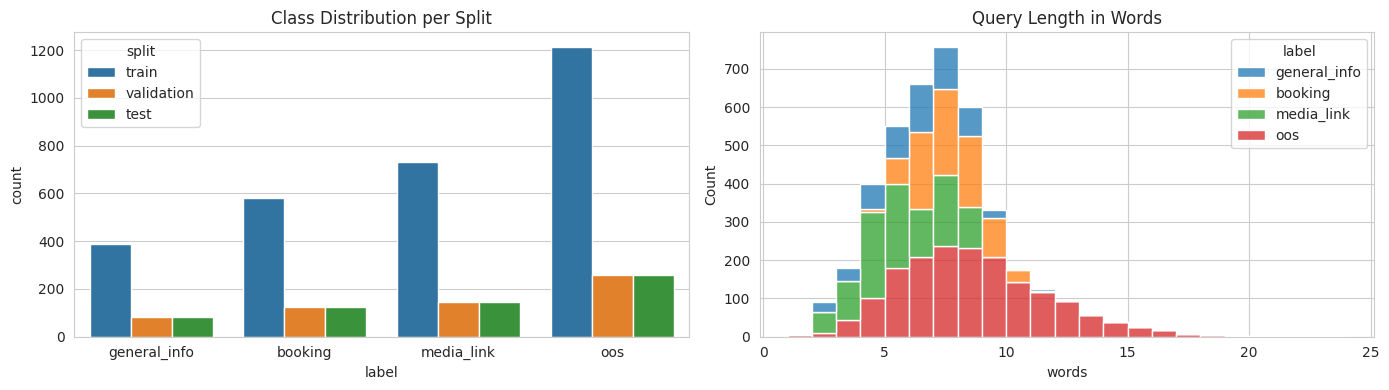

Sample test queries:
       label                                                   text
     booking    can i book a dociment verification slot on saturady
     booking                       can i book a campus visit on kal
     booking                               cancel my entry test sot
general_info                       cafeteria ke baare mein batayein
general_info                                is there a wfi on camus
general_info                                    llb ki fee ktni hai
  media_link                     do you have pictures of the mosque
  media_link                 do you have images of the girls hostel
  media_link                   do you have photos of the classrooms
         oos show me a tabulation of reviews for lcd tv's on amazon
         oos                                           king of acid
         oos                                  what color is the car


In [14]:
def group_split(data, fracs={"train": 0.70, "validation": 0.15, "test": 0.15}):
    assign = {}
    for _, g in data.groupby("label"):
        sizes = g.groupby("group").size().sample(frac=1, random_state=SEED)
        sizes = sizes.sort_values(ascending=False, kind="stable")
        total = sizes.sum()
        filled = dict.fromkeys(fracs, 0)
        for grp, n in sizes.items():
            target = max(fracs, key=lambda s: fracs[s] * total - filled[s])
            assign[grp] = target
            filled[target] += n
    return data["group"].map(assign)


df["split"] = group_split(df)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

overlap = set(train_df["group"]) & (set(val_df["group"]) | set(test_df["group"]))
print("Group overlap between train and val/test:", len(overlap))
print()
print(pd.crosstab(df["label"], df["split"], margins=True)[["train", "validation", "test", "All"]])

df["words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x="label", hue="split", order=LABEL_NAMES,
              hue_order=["train", "validation", "test"], ax=axes[0])
axes[0].set_title("Class Distribution per Split")
sns.histplot(data=df, x="words", hue="label", hue_order=LABEL_NAMES,
             bins=range(1, 25), multiple="stack", ax=axes[1])
axes[1].set_title("Query Length in Words")
plt.tight_layout()
plt.show()

print("Sample test queries:")
print(test_df.groupby("label").sample(3, random_state=SEED)[["label", "text"]].to_string(index=False))

## Step 5 | Baseline Model

Before fine-tuning a transformer, we train a simple and fast baseline: **TF-IDF + Logistic Regression**.
- Word n-grams capture key words like "fee", "book", "pictures"
- Character n-grams help with typos and Roman Urdu spelling variations

The baseline sets a minimum score. ModernBERT is only worth using if it clearly beats it.

In [15]:
from sklearn.pipeline import make_pipeline, make_union


def summarize(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }


baseline = make_pipeline(
    make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
    ),
    LogisticRegression(max_iter=2000, C=5, class_weight="balanced"),
)
baseline.fit(train_df["text"], train_df["label_id"])

base_summary = pd.DataFrame({
    name: summarize(split["label_id"], baseline.predict(split["text"]))
    for name, split in [("train", train_df), ("validation", val_df), ("test", test_df)]
}).round(4)
print(base_summary)
print()

BASE_TEST_PROBS = baseline.predict_proba(test_df["text"])
BASE_TEST_PRED = BASE_TEST_PROBS.argmax(1)
print(classification_report(test_df["label_id"], BASE_TEST_PRED, target_names=LABEL_NAMES, digits=4))

          train  validation    test
accuracy    1.0      0.8918  0.9098
macro_f1    1.0      0.8656  0.8904

              precision    recall  f1-score   support

general_info     1.0000    0.6024    0.7519        83
     booking     0.9756    0.9677    0.9717       124
  media_link     0.9843    0.8741    0.9259       143
         oos     0.8387    1.0000    0.9123       260

    accuracy                         0.9098       610
   macro avg     0.9496    0.8611    0.8904       610
weighted avg     0.9226    0.9098    0.9057       610



## Step 6 | Fine-Tuning ModernBERT

ModernBERT is already pretrained on a large amount of text, so it understands language. Fine-tuning updates its weights using our labeled queries so it learns these four routes.

Training settings:
- **Loss function**: cross-entropy, which punishes confident wrong predictions the most
- **Optimizer**: AdamW, Adam with weight decay
- **Learning rate**: 3e-5 with warmup and linear decay, small enough to avoid destroying pretrained knowledge
- **Weight decay**: 0.01, a regularization that keeps weights small
- **Early stopping**: training stops when validation loss stops improving for 2 epochs

Both train and validation loss are measured after every epoch, so we can check overfitting in Step 7.1.

In [16]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def to_dataset(split_df):
    ds = Dataset.from_pandas(split_df[["text", "label_id"]].rename(columns={"label_id": "labels"}))
    return ds.map(
        lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
        batched=True,
        remove_columns=["text"],
    )


train_ds = to_dataset(train_df)
val_ds = to_dataset(val_df)
test_ds = to_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_NAMES),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)


def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return summarize(p.label_ids, pred)


args = TrainingArguments(
    output_dir="/kaggle/working/checkpoints",
    num_train_epochs=10,
    learning_rate=3e-5,
    lr_scheduler_type="linear",
    warmup_steps=0.1,
    optim="adamw_torch",
    weight_decay=0.01,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_validation_loss",
    greater_is_better=False,
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset={"train": train_ds, "validation": val_ds},
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

trainer.train()

Map:   0%|          | 0/2910 [00:00<?, ? examples/s]

Map:   0%|          | 0/610 [00:00<?, ? examples/s]

Map:   0%|          | 0/610 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.


...

early stopping required metric_for_best_model, but did not find eval_validation_loss so early stopping is disabled


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

early stopping required metric_for_best_model, but did not find eval_validation_loss so early stopping is disabled


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=364, training_loss=0.14701987534843303, metrics={'train_runtime': 71.8963, 'train_samples_per_second': 404.749, 'train_steps_per_second': 12.657, 'total_flos': 146426741535168.0, 'train_loss': 0.14701987534843303, 'epoch': 4.0})

### Training Check

Confirm why training stopped: print the loss per epoch and the best checkpoint selected by early stopping.

In [17]:
history = pd.DataFrame(trainer.state.log_history)
epoch_log = history.groupby("epoch").first()[["eval_train_loss", "eval_validation_loss", "eval_validation_macro_f1"]]
print(epoch_log.round(4))
print()
print("Best validation loss:", round(trainer.state.best_metric, 4))
print("Best checkpoint:", trainer.state.best_model_checkpoint)

       eval_train_loss  eval_validation_loss  eval_validation_macro_f1
epoch                                                                 
1.0             0.0269                1.2713                    0.6767
2.0             0.0050                0.9419                    0.8338
3.0             0.0001                1.1200                    0.7628
4.0             0.0000                1.2769                    0.7725

Best validation loss: 0.9419
Best checkpoint: /kaggle/working/checkpoints/checkpoint-182


## Step 7 | Model Performance Evaluation

The fine-tuned model is evaluated from several angles:
1. Learning curves
2. Precision, recall and F1
3. Confusion matrix
4. Baseline vs ModernBERT comparison
5. Confidence calibration and OOS threshold
6. Error analysis

### Step 7.1 | Learning Curves Analysis

Train and validation loss are compared epoch by epoch:
- **Both losses high**: underfitting, the model has not learned enough
- **Train loss keeps falling but validation loss rises**: overfitting, the model is memorizing
- **Both low and close**: good fit

The dashed line marks the best epoch, which early stopping keeps as the final model.

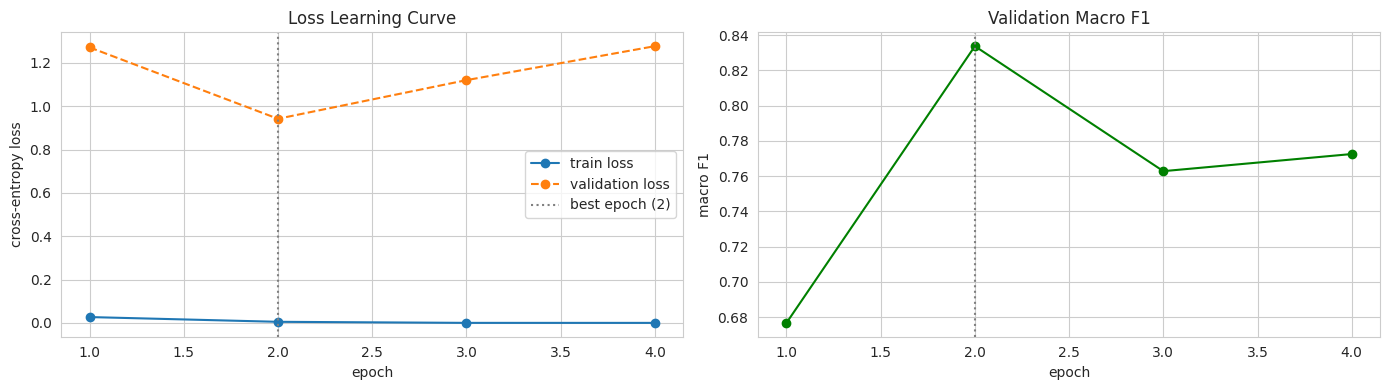

In [19]:
best_epoch = epoch_log["eval_validation_loss"].idxmin()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epoch_log.index, epoch_log["eval_train_loss"], "o-", label="train loss")
axes[0].plot(epoch_log.index, epoch_log["eval_validation_loss"], "o--", label="validation loss")
axes[0].axvline(best_epoch, color="gray", linestyle=":", label=f"best epoch ({best_epoch:.0f})")
axes[0].set_title("Loss Learning Curve")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend()

axes[1].plot(epoch_log.index, epoch_log["eval_validation_macro_f1"], "o-", color="green")
axes[1].axvline(best_epoch, color="gray", linestyle=":")
axes[1].set_title("Validation Macro F1")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("macro F1")
plt.tight_layout()
plt.show()

### Learning Curves Insight

- The model does not underfit: train loss drops close to zero within two epochs.
- Overfitting starts after epoch 2: train loss reaches zero while validation loss rises at epoch 3.
- Epoch 4 has a higher F1 but also a higher loss, meaning the model is right more often but very overconfident when wrong.
- Early stopping kept the epoch 2 model, which has the lowest validation loss and generalizes best.

### Step 7.2 | Precision, Recall and F1-Score

These metrics are measured per class on the test set:
- **Precision**: of all queries predicted as a route, how many were correct. Low precision means wrong queries are sent to that route.
- **Recall**: of all queries that truly belong to a route, how many were found. Low recall means real queries for that route are missed.
- **F1-score**: the balance of precision and recall in one number.
- **Macro average**: the simple average over all classes, so every route counts equally.

              precision    recall  f1-score   support

general_info     0.9032    0.6747    0.7724        83
     booking     0.8322    0.9597    0.8914       124
  media_link     0.9925    0.9301    0.9603       143
         oos     0.9299    0.9692    0.9492       260

    accuracy                         0.9180       610
   macro avg     0.9145    0.8834    0.8933       610
weighted avg     0.9211    0.9180    0.9160       610



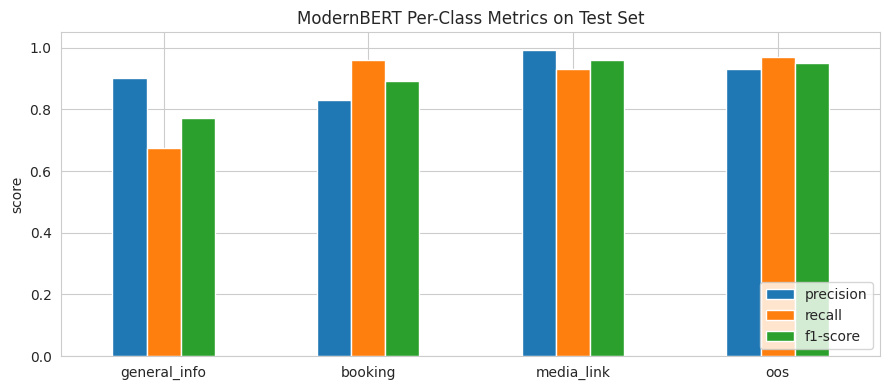

In [20]:
def get_logits(ds):
    out = trainer.predict(ds)
    return np.asarray(out.predictions, dtype=np.float32), out.label_ids


val_logits, val_labels = get_logits(val_ds)
test_logits, test_labels = get_logits(test_ds)

BERT_TEST_PROBS = softmax(test_logits, axis=1)
BERT_TEST_PRED = BERT_TEST_PROBS.argmax(1)

print(classification_report(test_labels, BERT_TEST_PRED, target_names=LABEL_NAMES, digits=4))

report = pd.DataFrame(
    classification_report(test_labels, BERT_TEST_PRED, target_names=LABEL_NAMES, output_dict=True)
).T.loc[LABEL_NAMES, ["precision", "recall", "f1-score"]]

report.plot(kind="bar", figsize=(9, 4), ylim=(0, 1.05), rot=0)
plt.title("ModernBERT Per-Class Metrics on Test Set")
plt.ylabel("score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Per-Class Metrics Insight

- media_link and oos are strong, with F1 above 0.94.
- general_info has the weakest recall (0.67): about one in three information queries is missed.
- booking has lower precision (0.83), which suggests the missed general_info queries are predicted as booking.
- Macro F1 (0.89) is lower than accuracy (0.92) because it gives the weak general_info class equal weight.

### Step 7.3 | Confusion Matrix Analysis

Rows are the true route and columns are the predicted route. The diagonal shows correct predictions, and every cell off the diagonal shows a specific mistake. The normalized matrix shows each row as a percentage, so classes of different sizes can be compared.

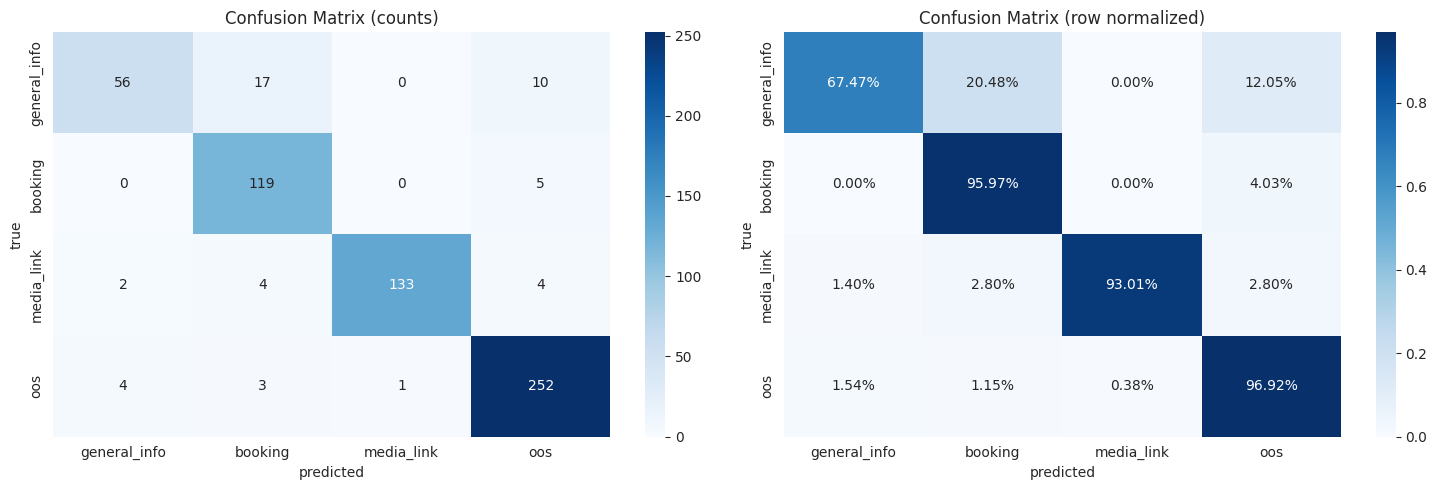

Biggest confusions (true -> predicted):
  17  general_info  -> booking
  10  general_info  -> oos
   5  booking       -> oos
   4  oos           -> general_info
   4  media_link    -> oos
   4  media_link    -> booking
   3  oos           -> booking
   2  media_link    -> general_info
   1  oos           -> media_link


In [21]:
cm = confusion_matrix(test_labels, BERT_TEST_PRED)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[1])
axes[1].set_title("Confusion Matrix (row normalized)")
for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
plt.tight_layout()
plt.show()

print("Biggest confusions (true -> predicted):")
off = [(cm[i, j], LABEL_NAMES[i], LABEL_NAMES[j])
       for i in range(len(LABEL_NAMES)) for j in range(len(LABEL_NAMES)) if i != j and cm[i, j] > 0]
for n, t, p in sorted(off, reverse=True):
    print(f"{n:>4}  {t:<13} -> {p}")

### Confusion Matrix Insight

- The biggest error is general_info predicted as booking (17 queries). Questions like "is a hostel available" share words and structure with booking requests like "is a campus visit available".
- The second error is general_info predicted as oos (10 queries), likely short or unusual information questions that look like general chit chat.
- Together, these make up about half of all test mistakes, so improving general_info data would give the largest gain.
- The other classes have only a few scattered mistakes.

### Step 7.4 | Baseline vs ModernBERT Comparison

Both models are compared on the same test set using overall scores, per-class F1 and confusion matrices. This shows whether fine-tuning a transformer is worth it over the simple baseline.

                 TF-IDF + LR  ModernBERT  difference
accuracy              0.9098      0.9180      0.0082
macro_f1              0.8904      0.8933      0.0029
f1_general_info       0.7519      0.7724      0.0205
f1_booking            0.9717      0.8914     -0.0803
f1_media_link         0.9259      0.9603      0.0344
f1_oos                0.9123      0.9492      0.0369


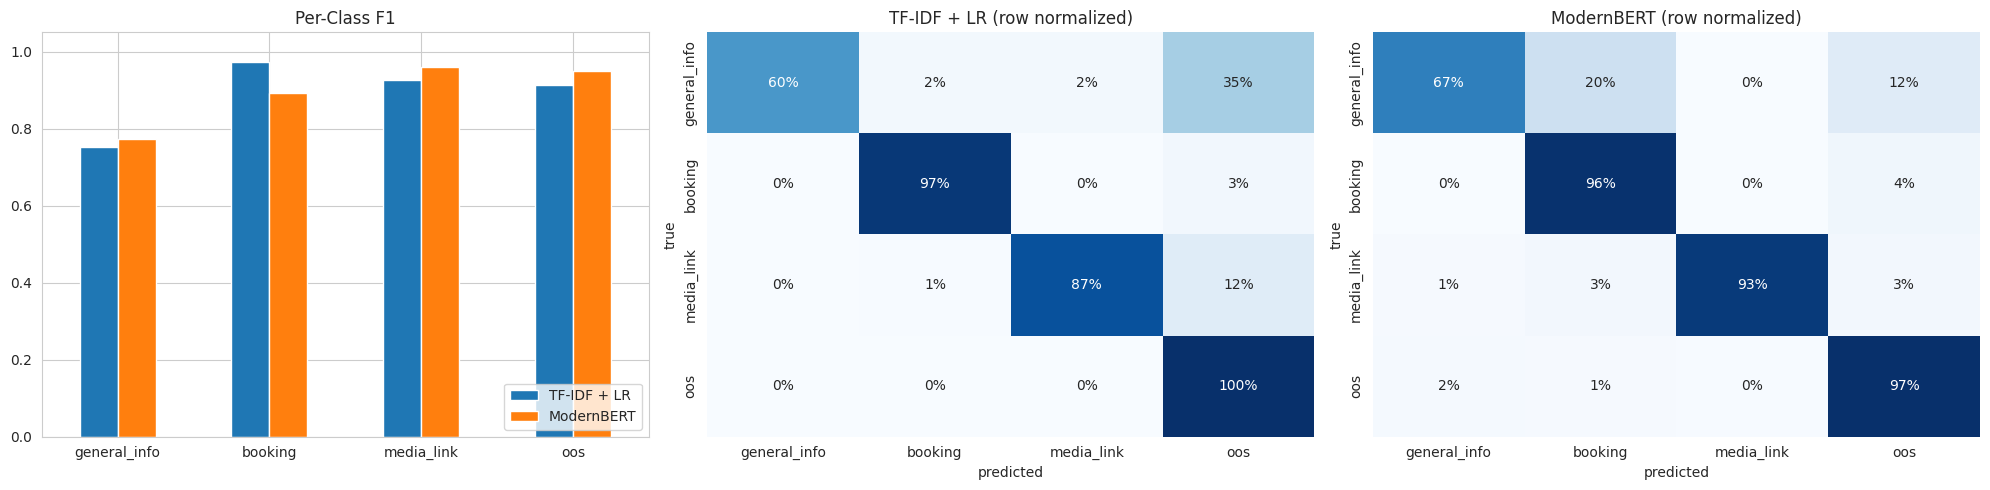

In [22]:
models = {"TF-IDF + LR": BASE_TEST_PRED, "ModernBERT": BERT_TEST_PRED}

overall = pd.DataFrame({name: summarize(test_labels, pred) for name, pred in models.items()})
per_class = pd.DataFrame({
    name: f1_score(test_labels, pred, average=None, labels=range(len(LABEL_NAMES)))
    for name, pred in models.items()
}, index=[f"f1_{n}" for n in LABEL_NAMES])

comparison = pd.concat([overall, per_class]).round(4)
comparison["difference"] = (comparison["ModernBERT"] - comparison["TF-IDF + LR"]).round(4)
print(comparison)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
per_class.rename(index=lambda s: s[3:]).plot(kind="bar", ax=axes[0], ylim=(0, 1.05), rot=0)
axes[0].set_title("Per-Class F1")
axes[0].legend(loc="lower right")
for ax, (name, pred) in zip(axes[1:], models.items()):
    cm_n = confusion_matrix(test_labels, pred, normalize="true")
    sns.heatmap(cm_n, annot=True, fmt=".0%", cmap="Blues", cbar=False,
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax)
    ax.set_title(f"{name} (row normalized)")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
plt.tight_layout()
plt.show()

### Comparison Insight

- ModernBERT is only slightly better overall: +0.8% accuracy and +0.3% macro F1.
- The baseline wins on booking (0.97 vs 0.89), because booking queries rely on strong keywords like "book", "schedule" and "cancel". ModernBERT over-predicts booking.
- ModernBERT wins on general_info, media_link and oos, where understanding meaning matters more than matching keywords.
- The gap is small because the dataset is template based and keyword heavy, which suits TF-IDF. The real advantage of ModernBERT should appear on natural user queries, which is tested in Step 8.

### Step 7.5 | Confidence Calibration and OOS Threshold

A model is **calibrated** when its confidence matches its accuracy: predictions at 90% confidence should be right about 90% of the time. Fine-tuned models are often overconfident.

- **Temperature scaling** divides the logits by one value T, learned on the validation set. It changes confidence but never changes the predicted class.
- **ECE (Expected Calibration Error)** measures the gap between confidence and accuracy. Lower is better.
- **OOS threshold**: if the top confidence is below the threshold, the query is routed to oos. The threshold is chosen on validation to balance in-scope accuracy and oos recall.

Temperature: 3.130
ECE before: 0.0557  after: 0.0896
Best threshold (chosen on validation): 0.0

              no threshold  threshold 0.0
accuracy            0.9180         0.9180
in_scope_acc        0.8800         0.8800
oos_recall          0.9692         0.9692
macro_f1            0.8933         0.8933


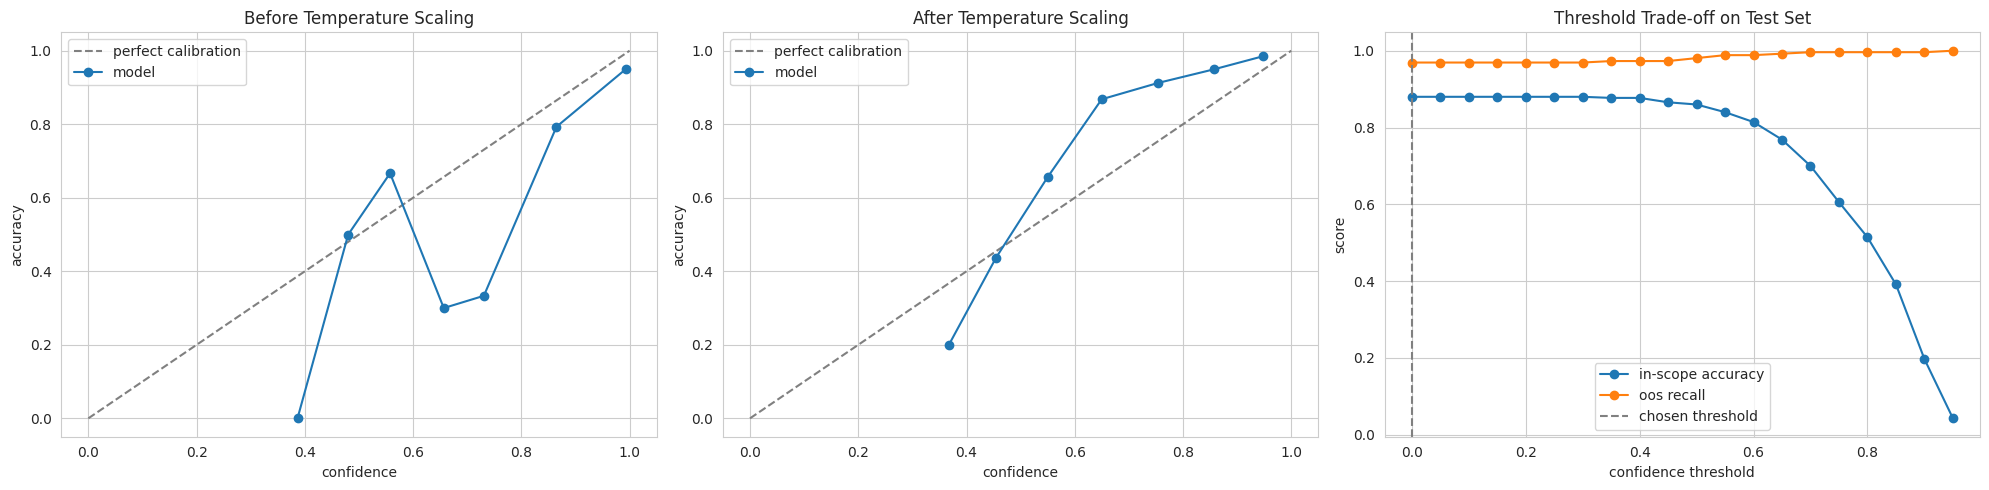

In [23]:
def fit_temperature(logits, labels):
    lg = torch.tensor(logits)
    lb = torch.tensor(labels, dtype=torch.long)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(lg / log_t.exp(), lb)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_t.exp().item())


def ece(probs, labels, bins=15):
    conf = probs.max(1)
    correct = probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total


def predict(probs, threshold=0.0):
    return np.where(probs.max(1) < threshold, OOS_ID, probs.argmax(1))


def oos_scores(probs, labels, threshold=0.0):
    pred = predict(probs, threshold)
    ins = labels != OOS_ID
    return {
        "accuracy": float((pred == labels).mean()),
        "in_scope_acc": float((pred[ins] == labels[ins]).mean()),
        "oos_recall": float((pred[~ins] == OOS_ID).mean()),
        "macro_f1": float(f1_score(labels, pred, average="macro")),
    }


def reliability(ax, probs, labels, title, bins=10):
    conf = probs.max(1)
    correct = probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            xs.append(conf[m].mean())
            ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.plot(xs, ys, "o-", label="model")
    ax.set_title(title)
    ax.set_xlabel("confidence")
    ax.set_ylabel("accuracy")
    ax.legend()


TEMPERATURE = fit_temperature(val_logits, val_labels)
val_probs = softmax(val_logits / TEMPERATURE, axis=1)
test_probs = softmax(test_logits / TEMPERATURE, axis=1)

print(f"Temperature: {TEMPERATURE:.3f}")
print(f"ECE before: {ece(BERT_TEST_PROBS, test_labels):.4f}  after: {ece(test_probs, test_labels):.4f}")

thresholds = np.round(np.arange(0.0, 0.96, 0.05), 2)
val_curve = [oos_scores(val_probs, val_labels, t) for t in thresholds]
balanced = [(s["in_scope_acc"] + s["oos_recall"]) / 2 for s in val_curve]
BEST_THRESHOLD = float(thresholds[int(np.argmax(balanced))])
print("Best threshold (chosen on validation):", BEST_THRESHOLD)
print()
print(pd.DataFrame({
    "no threshold": oos_scores(test_probs, test_labels, 0.0),
    f"threshold {BEST_THRESHOLD}": oos_scores(test_probs, test_labels, BEST_THRESHOLD),
}).round(4))

test_curve = [oos_scores(test_probs, test_labels, t) for t in thresholds]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
reliability(axes[0], BERT_TEST_PROBS, test_labels, "Before Temperature Scaling")
reliability(axes[1], test_probs, test_labels, "After Temperature Scaling")
axes[2].plot(thresholds, [s["in_scope_acc"] for s in test_curve], "o-", label="in-scope accuracy")
axes[2].plot(thresholds, [s["oos_recall"] for s in test_curve], "o-", label="oos recall")
axes[2].axvline(BEST_THRESHOLD, color="gray", linestyle="--", label="chosen threshold")
axes[2].set_title("Threshold Trade-off on Test Set")
axes[2].set_xlabel("confidence threshold")
axes[2].set_ylabel("score")
axes[2].legend()
plt.tight_layout()
plt.show()

In [ ]:
### Comparison Insight

- ModernBERT is only slightly better overall: +0.8% accuracy and +0.3% macro F1.
- The baseline wins on booking (0.97 vs 0.89), because booking queries rely on strong keywords like "book", "schedule" and "cancel". ModernBERT over-predicts booking.
- ModernBERT wins on general_info, media_link and oos, where understanding meaning matters more than matching keywords.
- The gap is small because the dataset is template based and keyword heavy, which suits TF-IDF. The real advantage of ModernBERT should appear on natural user queries, which is tested in Step 8.

### Step 7.6 | Error Analysis

Metrics show how many mistakes happen. Error analysis shows which queries fail and why. We look at:
- Mistakes grouped by data source (template, seed, typo, CLINC)
- The most confident mistakes, which are the most dangerous in production
- Example failures for the biggest confusion pairs

In [24]:
errors = test_df.copy()
errors["pred"] = [ID2LABEL[int(i)] for i in BERT_TEST_PRED]
errors["conf"] = BERT_TEST_PROBS.max(1)
errors["correct"] = errors["pred"] == errors["label"]

print("Error rate by source:")
print(errors.groupby("source")["correct"].agg(total="size", errors=lambda s: (~s).sum(),
                                                error_rate=lambda s: round(1 - s.mean(), 4)))
print()

wrong = errors[~errors["correct"]].sort_values("conf", ascending=False)
print("Most confident mistakes:")
print(wrong.head(12)[["conf", "label", "pred", "source", "text"]].round(3).to_string(index=False))
print()

for true_label, pred_label in [("general_info", "booking"), ("general_info", "oos")]:
    sample = wrong[(wrong["label"] == true_label) & (wrong["pred"] == pred_label)]
    print(f"{true_label} -> {pred_label} ({len(sample)} queries):")
    for text in sample["text"].head(8):
        print("  ", text)
    print()

Error rate by source:
              total  errors  error_rate
source                                 
clinc_intent     15       0      0.0000
clinc_oos       241       7      0.0290
seed             40      15      0.3750
template        236      15      0.0636
typo             78      13      0.1667

Most confident mistakes:
 conf        label    pred   source                                        text
1.000 general_info booking     typo            trransport ke baare min batayein
1.000 general_info booking template               hostel ke baare mein batayein
1.000          oos booking     seed                        aaj mausam kaisa hai
1.000 general_info     oos     seed              what is the last date to apply
1.000 general_info     oos     typo                          entry tset kab hai
1.000 general_info     oos     seed           can i pay the fee in installments
1.000      booking     oos     typo can i boook a orientation sesison on parson
1.000 general_info     oos     s

### Error Analysis Insight

- **Shortcut learning**: every "... ke baare mein batayein" query was predicted as booking with 100% confidence. Booking has more Roman Urdu templates in training, so the model learned "Roman Urdu style means booking" instead of the meaning.
- **Narrow general_info data**: hand-written seed queries fail at 37.5% versus 6% for templates. Topics like deadlines, documents, location, merit lists and installments are missing from the templates, so these questions fall into oos.
- **Confident mistakes**: most errors have confidence near 1.0, so no threshold can catch them. The fix must come from the data, not the model settings.
- The high test score on templates hides these issues. This is why error analysis matters beyond metrics.

### Save Model A

Before changing the data, the current model (Model A) is saved to disk with its tokenizer and router settings. This keeps it safe if the session restarts, and lets us compare it with the improved model later. A reference `A_TRAINER` is also kept in memory so the next training does not overwrite it.

In [25]:
import json

MODEL_A_DIR = "/kaggle/working/router_v1"
A_TRAINER = trainer

A_TRAINER.save_model(MODEL_A_DIR)
tokenizer.save_pretrained(MODEL_A_DIR)

with open(os.path.join(MODEL_A_DIR, "router_config.json"), "w") as f:
    json.dump({
        "labels": LABEL_NAMES,
        "temperature": TEMPERATURE,
        "threshold": BEST_THRESHOLD,
        "max_len": MAX_LEN,
        "best_checkpoint": A_TRAINER.state.best_model_checkpoint,
    }, f, indent=2)

print("Saved Model A to:", MODEL_A_DIR)
print(sorted(os.listdir(MODEL_A_DIR)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved Model A to: /kaggle/working/router_v1
['config.json', 'model.safetensors', 'router_config.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


### Step 7.7 | Improving the Model

Error analysis showed two data problems: narrow general_info topics and unbalanced Roman Urdu across classes. We fix the data, retrain, and compare.

#### Step 7.7.1 | Improved Dataset and Real-World Eval Set

Changes to the data:
- **More general_info topics**: deadlines, documents, merit list, scholarships, installments, location, timings, contact
- **Balanced Roman Urdu**: every class, including oos, gets Roman Urdu templates
- **Contrast pairs**: the same object appears in different routes, for example "hostel ke baare mein batayein" (info), "hostel visit book karni hai" (booking), "hostel ki pictures chahiye" (media). The model must learn intent, not keywords.

A separate **real-world eval set** of hand-written natural queries is created. It is never used for training, so both the old and new models can be compared fairly on it.

In [26]:
SLOTS_V2 = {
    **SLOTS,
    "info_topic": ["last date to apply", "admission deadline", "required documents", "merit list", "scholarship",
                   "fee installments", "fee structure", "entry test date", "result", "class timings",
                   "semester start date", "contact number", "office timings", "refund policy", "age limit"],
    "info_topic_ur": ["last date", "documents", "merit list", "scholarship", "installments", "fee structure",
                      "test ki date", "result", "classes ka time", "semester start", "contact number",
                      "office ka time", "refund", "age limit"],
    "obj": ["hostel", "library", "cafeteria", "sports complex", "computer lab", "auditorium", "mosque",
            "medical center", "girls hostel", "boys hostel"],
    "city": ["lahore", "multan", "karachi", "islamabad", "dubai", "london"],
    "oos_topic": ["weather", "gold rate", "dollar rate", "petrol price", "local time", "news"],
    "oos_topic_ur": ["mausam", "cricket score", "gold rate", "dollar rate", "petrol ki price", "khabrein"],
}

EXTRA_TEMPLATES = {
    "general_info": [
        "what is the {info_topic}",
        "tell me the {info_topic} for {program}",
        "i need information about the {info_topic}",
        "can you tell me about the {info_topic} for {program}",
        "{info_topic_ur} kya hai",
        "{info_topic_ur} kab hai",
        "{program} ka {info_topic_ur} batayein",
        "{info_topic_ur} ke baare mein batayein",
        "mujhe {info_topic_ur} ka pata karna hai",
        "{obj} ke baare mein batayein",
        "{obj} ki details chahiye",
        "what facilities does the {obj} have",
        "where is the {obj} located",
        "{obj} kahan hai",
        "is the {obj} open on {day}",
    ],
    "booking": [
        "book a visit to the {obj} for {day}",
        "{obj} visit book karni hai",
        "{day} ko {obj} dekhne aana hai time de dein",
        "i want to visit the {obj} on {day}",
        "mujhe {day} ka slot chahiye {item} ke liye",
        "{item} ke liye time chahiye",
        "{item} cancel kar dein",
        "meri {item} {day} par shift kar dein",
    ],
    "media_link": [
        "{obj} ki pictures chahiye",
        "{obj} ki tasveerein bhejo",
        "send a video of the {obj}",
        "{obj} ki video hai kya",
        "mujhe {obj} ki photos dekhni hain",
        "{obj} andar se kaisa dikhta hai pics bhejo",
    ],
    "oos": [
        "aaj {city} mein {oos_topic_ur} kya hai",
        "{city} ka {oos_topic_ur} batao",
        "what is the {oos_topic} in {city}",
        "{city} ki ticket book karo",
        "{city} ke liye flight book kar do",
        "{city} mein acha restaurant kaun sa hai",
        "{oos_topic_ur} ke baare mein batao",
        "mujhe {city} jana hai cab book karo",
    ],
}

TEMPLATES_V2 = {label: TEMPLATES[label] + EXTRA_TEMPLATES[label] for label in LABEL_NAMES}

REAL_EVAL = {
    "general_info": [
        "how many semesters are there in bs cs", "what is the minimum percentage required for engineering",
        "do you have a quota for sports students", "is there any need based financial aid",
        "what are the passing marks of the entry test", "are classes on weekends too",
        "who is the head of the cs department", "is hostel compulsory for outstation students",
        "kya fee wapis milti hai agar admission chor dein", "bs ke liye kitne numbers chahiye",
        "kya weekend pe bhi classes hoti hain", "transport ka route kya hai", "second merit list kab lagegi",
        "online apply kaise karte hain", "is there a dress code", "can foreign students apply",
        "what is the fee for the second semester", "kya hafiz e quran ko extra marks milte hain",
        "campus mein atm hai", "how far is the campus from the bus stop",
    ],
    "booking": [
        "i would like to come and see the campus next thursday", "please arrange a meeting with the hostel warden",
        "can someone from admissions call me tomorrow at 11", "put my name down for the open day",
        "i cannot make it on friday, move my visit to monday", "is there room for two more people on the saturday tour",
        "main apne parents ke saath campus aana chahta hun time de dein", "mera interview agle hafte rakh dein",
        "warden se milne ka time chahiye", "meri appointment aage kar dein",
        "sign me up for the career counseling workshop", "i need to drop my documents, when can i come",
        "can i get a slot to retake the entry test", "cancel tomorrow's meeting please",
        "arrange a lab visit for my son", "admission office mein milne ke liye waqt chahiye",
        "saturday wala tour confirm kar dein", "we are a group of 10 students, can we schedule a tour",
        "book me in for the scholarship interview", "orientation mein mera naam likh lein",
    ],
    "media_link": [
        "what do the dorms look like inside", "i want to see how big the library is, any pics",
        "share the photos of last year's sports gala", "any snaps of the new block",
        "show me a drone view of the university", "hostel ka kamra kaisa dikhta hai photo bhejo",
        "convocation ki video share karein", "labs ki koi tasveer hai", "campus ka nazara dikhayein",
        "can you send a picture of the admission office building", "let me see the girls common room",
        "photos of the food served in the mess", "is there a youtube video of campus life",
        "show the swimming pool", "meri ammi campus dekhna chahti hain pictures bhejo",
        "send me the prospectus pictures", "what does the parking area look like",
        "cafe ka andar se view dikhao", "show me photos from the annual dinner", "any video of the robotics lab",
    ],
    "oos": [
        "who is the prime minister of pakistan", "what is 25 times 4", "help me write a cover letter",
        "find me a cheap hotel in murree", "best phone under 50000", "mujhe neend nahi aa rahi",
        "kal match kaun jeeta", "chai kaise banate hain", "uber book kar do", "remind me to drink water",
        "how do i make a website", "recommend a netflix series", "mera parcel kahan hai",
        "lahore se islamabad kitni door hai", "what is the meaning of life", "i am bored",
        "apna naam batao", "bitcoin ki price kya hai", "how to cook pasta", "thank you so much",
    ],
}

real_df = pd.DataFrame([{"text": t, "label": label} for label, texts in REAL_EVAL.items() for t in texts])
real_df["label_id"] = real_df["label"].map(LABEL2ID)


def expand_with(template, slots, r):
    keys = re.findall(r"\{(\w+)\}", template)
    combos = list(itertools.product(*(slots[k] for k in keys)))
    r.shuffle(combos)
    return [template.format(**dict(zip(keys, c))) for c in combos[:PER_TEMPLATE]]


def build_dataset(templates, slots, cap):
    r = random.Random(SEED)
    rows = []
    for label, tmpl_list in templates.items():
        for t_id, template in enumerate(tmpl_list):
            rows += [{"text": text, "label": label, "group": f"{label}_t{t_id}", "source": "template"}
                     for text in expand_with(template, slots, r)]
    for label, route in ROUTES.items():
        rows += [{"text": ex, "label": label, "group": f"{label}_seed{j}", "source": "seed"}
                 for j, ex in enumerate(route["examples"])]

    by_intent = {}
    for split in clinc:
        for ex in clinc[split]:
            by_intent.setdefault(clinc_names[ex["intent"]], []).append(ex["text"])
    for k, text in enumerate(by_intent.pop("oos")):
        rows.append({"text": text, "label": "oos", "group": f"clinc_oos_{k}", "source": "clinc_oos"})
    for intent, texts in by_intent.items():
        if intent not in EXCLUDED_CLINC:
            rows += [{"text": text, "label": "oos", "group": f"clinc_{intent}", "source": "clinc_intent"}
                     for text in r.sample(texts, min(CLINC_PER_INTENT, len(texts)))]

    data = pd.DataFrame(rows)
    data["text"] = data["text"].str.strip().str.lower()
    data = data[~data["text"].isin(real_df["text"])]
    conflicts = data.groupby("text")["label"].nunique()
    data = data[~data["text"].isin(conflicts[conflicts > 1].index)].drop_duplicates("text")
    data = (data.groupby("label", group_keys=False)
                .apply(lambda g: g.sample(min(len(g), cap), random_state=SEED))
                .reset_index(drop=True))

    typos = data[data["source"] != "clinc_oos"].sample(frac=TYPO_RATIO, random_state=SEED).copy()
    typos["text"] = [add_typos(t, r) for t in typos["text"]]
    typos["source"] = "typo"
    typos = typos[~typos["text"].isin(data["text"])]

    data = pd.concat([data, typos]).drop_duplicates("text").sample(frac=1, random_state=SEED).reset_index(drop=True)
    data["label_id"] = data["label"].map(LABEL2ID)
    return data


df_v2 = build_dataset(TEMPLATES_V2, SLOTS_V2, cap=2500)

UR_MARKERS = r"\b(hai|hain|karo|kar|dein|chahiye|batayein|batao|bhejo|dikhao|kya|kab|kahan|mein|ke|ki|ka)\b"
ur_share = pd.DataFrame({
    "v1 roman urdu %": df.groupby("label")["text"].apply(lambda s: s.str.contains(UR_MARKERS).mean()),
    "v2 roman urdu %": df_v2.groupby("label")["text"].apply(lambda s: s.str.contains(UR_MARKERS).mean()),
}).loc[LABEL_NAMES].mul(100).round(1)

print("Rows v1:", len(df), "| rows v2:", len(df_v2), "| real eval:", len(real_df))
print()
print(pd.crosstab(df_v2["label"], df_v2["source"], margins=True))
print()
print(ur_share)

Rows v1: 4130 | rows v2: 6519 | real eval: 80

source        clinc_intent  clinc_oos  seed  template  typo   All
label                                                            
booking                  0          0    27      1040   335  1402
general_info             0          0    25       850   261  1136
media_link               0          0    23       822   242  1087
oos                   1188       1148    25       139   394  2894
All                   1188       1148   100      2851  1232  6519

              v1 roman urdu %  v2 roman urdu %
label                                         
general_info             30.0             32.8
booking                  28.1             42.4
media_link               33.2             35.9
oos                       0.6              5.1


/tmp/ipykernel_58/2175685181.py:150: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), cap), random_state=SEED))
/tmp/ipykernel_58/2175685181.py:167: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "v1 roman urdu %": df.groupby("label")["text"].apply(lambda s: s.str.contains(UR_MARKERS).mean()),
/tmp/ipykernel_58/2175685181.py:168: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "v2 roman urdu %": df_v2.groupby("label")["text"].apply(lambda s: s.str.contains(UR_MARKERS).mean()),


#### Step 7.7.2 | Training Model B on the Improved Data

The improved data is split with the same group-wise method as Step 4. Model B is trained with exactly the same settings as Model A, so any difference in results comes from the data alone. It uses a separate checkpoint folder so Model A stays untouched. The baseline is also retrained on the new data for a fair comparison.

In [27]:
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

df_v2["split"] = group_split(df_v2)
train_v2 = df_v2[df_v2["split"] == "train"].reset_index(drop=True)
val_v2 = df_v2[df_v2["split"] == "validation"].reset_index(drop=True)
test_v2 = df_v2[df_v2["split"] == "test"].reset_index(drop=True)
print(pd.crosstab(df_v2["label"], df_v2["split"], margins=True)[["train", "validation", "test", "All"]])
print()

train_ds_v2 = to_dataset(train_v2)
val_ds_v2 = to_dataset(val_v2)
test_ds_v2 = to_dataset(test_v2)

baseline_v2 = make_pipeline(
    make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
    ),
    LogisticRegression(max_iter=2000, C=5, class_weight="balanced"),
)
baseline_v2.fit(train_v2["text"], train_v2["label_id"])

model_b = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_NAMES),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

args_b = TrainingArguments(
    output_dir="/kaggle/working/checkpoints_v2",
    num_train_epochs=10,
    learning_rate=3e-5,
    lr_scheduler_type="linear",
    warmup_steps=0.1,
    optim="adamw_torch",
    weight_decay=0.01,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_validation_loss",
    greater_is_better=False,
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

B_TRAINER = Trainer(
    model=model_b,
    args=args_b,
    train_dataset=train_ds_v2,
    eval_dataset={"train": train_ds_v2, "validation": val_ds_v2},
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

B_TRAINER.train()

history_b = pd.DataFrame(B_TRAINER.state.log_history)
epoch_log_b = history_b.groupby("epoch").first()[["eval_train_loss", "eval_validation_loss", "eval_validation_macro_f1"]]
print(epoch_log_b.round(4))
print()
print("Best validation loss:", round(B_TRAINER.state.best_metric, 4))
print("Best checkpoint:", B_TRAINER.state.best_model_checkpoint)

split         train  validation  test   All
label                                      
booking         982         210   210  1402
general_info    795         171   170  1136
media_link      761         163   163  1087
oos            2026         434   434  2894
All            4564         978   977  6519



Map:   0%|          | 0/4564 [00:00<?, ? examples/s]

Map:   0%|          | 0/978 [00:00<?, ? examples/s]

Map:   0%|          | 0/977 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

...

{'loss': '5.581e-05', 'grad_norm': '0.0002528', 'learning_rate': '1.676e-05', 'epoch': '5'}
{'eval_train_loss': '5.116e-06', 'eval_train_accuracy': '1', 'eval_train_macro_f1': '1', 'eval_train_runtime': '3.08', 'eval_train_samples_per_second': '1482', 'eval_train_steps_per_second': '11.69', 'epoch': '5'}
{'eval_validation_loss': '0.7605', 'eval_validation_accuracy': '0.8865', 'eval_validation_macro_f1': '0.8708', 'eval_validation_runtime': '0.6043', 'eval_validation_samples_per_second': '1618', 'eval_validation_steps_per_second': '13.24', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '6.292e-06', 'grad_norm': '0.005009', 'learning_rate': '1.343e-05', 'epoch': '6'}
{'eval_train_loss': '3.489e-06', 'eval_train_accuracy': '1', 'eval_train_macro_f1': '1', 'eval_train_runtime': '3.178', 'eval_train_samples_per_second': '1436', 'eval_train_steps_per_second': '11.33', 'epoch': '6'}
{'eval_validation_loss': '0.7862', 'eval_validation_accuracy': '0.8865', 'eval_validation_macro_f1': '0.8708', 'eval_validation_runtime': '0.6172', 'eval_validation_samples_per_second': '1585', 'eval_validation_steps_per_second': '12.96', 'epoch': '6'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '159', 'train_samples_per_second': '287', 'train_steps_per_second': '8.991', 'train_loss': '0.09454', 'epoch': '6'}
       eval_train_loss  eval_validation_loss  eval_validation_macro_f1
epoch                                                                 
1.0             0.0655                1.1991                    0.7552
2.0             0.0044                0.8588                    0.8531
3.0             0.0004                0.8170                    0.8633
4.0             0.0001                0.5938                    0.8866
5.0             0.0000                0.7605                    0.8708
6.0             0.0000                0.7862                    0.8708

Best validation loss: 0.5938
Best checkpoint: /kaggle/working/checkpoints_v2/checkpoint-572


### Model B Training Insight

- Model B reaches its best validation loss at epoch 4 (0.594, macro F1 0.887), and early stopping ends training at epoch 6.
- These numbers look worse than Model A (0.137, F1 0.931), but they are not comparable: Model B is validated on a harder and more diverse set of unseen templates.
- Both models overfit the template data (train loss near zero), and the gap is larger for Model B because its validation templates are more different from training.
- Model A and Model B cannot be tested on each other's test sets because of template overlap. The only fair comparison is the hand-written real-world eval set.

#### Step 7.7.3 | Before vs After on the Real-World Eval Set

All four models are evaluated on the same 80 hand-written queries that no model has seen in training:
- Baseline v1 and Model A, trained on the original data
- Baseline v2 and Model B, trained on the improved data

This shows whether fixing the data actually improved routing on natural user queries.

Map:   0%|          | 0/80 [00:00<?, ? examples/s]

                 Baseline v1  Model A  Baseline v2  Model B
accuracy              0.5000   0.5250       0.6000   0.7000
macro_f1              0.5024   0.5299       0.6140   0.7019
f1_general_info       0.3077   0.4286       0.5625   0.5806
f1_booking            0.5714   0.5333       0.6207   0.8095
f1_media_link         0.6667   0.6667       0.7273   0.7879
f1_oos                0.4638   0.4912       0.5455   0.6296



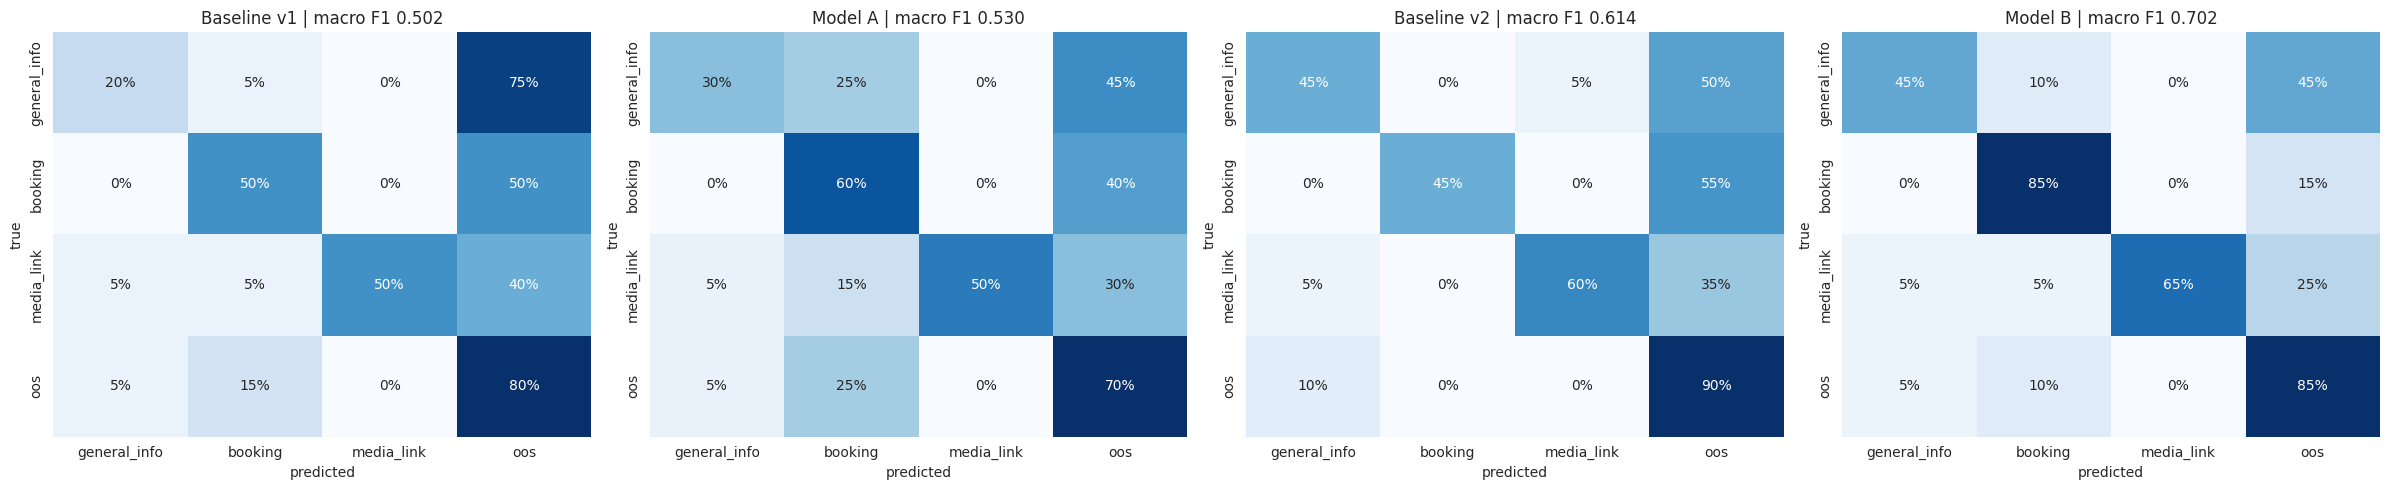

Fixed by Model B: 18 | broken by Model B: 4 | wrong in both: 20

Fixed:
       label      model_a      model_b                                                   text
general_info          oos general_info                  how many semesters are there in bs cs
general_info          oos general_info                do you have a quota for sports students
general_info          oos general_info           what are the passing marks of the entry test
general_info          oos general_info                            are classes on weekends too
general_info      booking general_info           is hostel compulsory for outstation students
general_info          oos general_info                             transport ka route kya hai
general_info      booking general_info                                    campus mein atm hai
     booking          oos      booking  i would like to come and see the campus next thursday
     booking          oos      booking    i cannot make it on friday, move my visi

In [28]:
real_ds = to_dataset(real_df)


def bert_probs(tr, ds):
    return softmax(np.asarray(tr.predict(ds).predictions, dtype=np.float32), axis=1)


real_probs = {
    "Baseline v1": baseline.predict_proba(real_df["text"]),
    "Model A": bert_probs(A_TRAINER, real_ds),
    "Baseline v2": baseline_v2.predict_proba(real_df["text"]),
    "Model B": bert_probs(B_TRAINER, real_ds),
}
real_pred = {name: p.argmax(1) for name, p in real_probs.items()}
y_real = real_df["label_id"].values

overall = pd.DataFrame({name: summarize(y_real, pred) for name, pred in real_pred.items()})
per_class = pd.DataFrame({
    name: f1_score(y_real, pred, average=None, labels=range(len(LABEL_NAMES)))
    for name, pred in real_pred.items()
}, index=[f"f1_{n}" for n in LABEL_NAMES])
print(pd.concat([overall, per_class]).round(4))
print()

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, (name, pred) in zip(axes, real_pred.items()):
    sns.heatmap(confusion_matrix(y_real, pred, normalize="true"), annot=True, fmt=".0%", cmap="Blues",
                cbar=False, xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax)
    ax.set_title(f"{name} | macro F1 {f1_score(y_real, pred, average='macro'):.3f}")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
plt.tight_layout()
plt.show()

changes = real_df.assign(
    model_a=[ID2LABEL[int(i)] for i in real_pred["Model A"]],
    model_b=[ID2LABEL[int(i)] for i in real_pred["Model B"]],
)
fixed = changes[(changes["model_a"] != changes["label"]) & (changes["model_b"] == changes["label"])]
broken = changes[(changes["model_a"] == changes["label"]) & (changes["model_b"] != changes["label"])]
still_wrong = changes[(changes["model_a"] != changes["label"]) & (changes["model_b"] != changes["label"])]

print(f"Fixed by Model B: {len(fixed)} | broken by Model B: {len(broken)} | wrong in both: {len(still_wrong)}")
print()
for title, part in [("Fixed", fixed), ("Broken", broken), ("Still wrong", still_wrong)]:
    print(f"{title}:")
    print(part[["label", "model_a", "model_b", "text"]].to_string(index=False) if len(part) else "  none")
    print()

### Before vs After Insight

| Model | Data | Real-world accuracy | Macro F1 |
|---|---|---|---|
| Baseline v1 | original | 0.500 | 0.502 |
| Model A | original | 0.525 | 0.530 |
| Baseline v2 | improved | 0.600 | 0.614 |
| Model B | improved | 0.700 | 0.702 |

- **Template test scores overestimate real performance**: Model A scored 0.918 on template test data but only 0.525 on natural queries.
- **Data matters more than the model**: switching to ModernBERT on the original data gave +2.5 points, while fixing the data gave +17.5 points for ModernBERT and +10 for the baseline.
- **Transformers benefit more from diverse data**: on the improved data, Model B beats the baseline by 10 points instead of 2.5.
- Model B fixed 18 queries and broke 4, all of them general_info topics missing from training (department head, dress code, foreign students).
- **Remaining errors**: unseen questions default to oos (the largest class), some Roman Urdu still goes to booking, and media or booking requests without clear keywords ("look like inside", "put my name down") are missed.
- **Best next step**: collect real user queries from logs and add them to training. The eval set has only 80 queries, so these numbers show the trend, not a final score.

## Step 8 | Inference

The router takes a user query and returns a confidence score for every route. The scores come from softmax over the model logits, so they always add up to 100%. The route with the highest score is selected.

- `route(query)`: returns the selected route, its confidence and the score of every route
- `route_table(queries)`: scores many queries at once and shows them as a table and chart

{
  "query": "bs computer science ki fee kitni hai",
  "route": "general_info",
  "confidence": 98.28,
  "scores": {
    "general_info": 98.28,
    "media_link": 1.02,
    "booking": 0.57,
    "oos": 0.13
  }
}
                                               route  confidence  general_info    booking  media_link        oos
what is the last date to apply for mba  general_info   93.040001     93.040001   0.710000    0.570000   5.680000
hostel ke baare mein batayein           general_info   95.199997     95.199997   2.730000    0.650000   1.420000
book a campus visit for saturday             booking   99.129997      0.420000  99.129997    0.350000   0.100000
meri appointment cancel kar dein             booking   98.860001      0.590000  98.860001    0.350000   0.200000
send me pictures of the girls hostel      media_link   98.980003      0.520000   0.300000   98.980003   0.200000
library ki video hai kya                general_info   63.360001     63.360001   2.680000   27.170000   6.80000

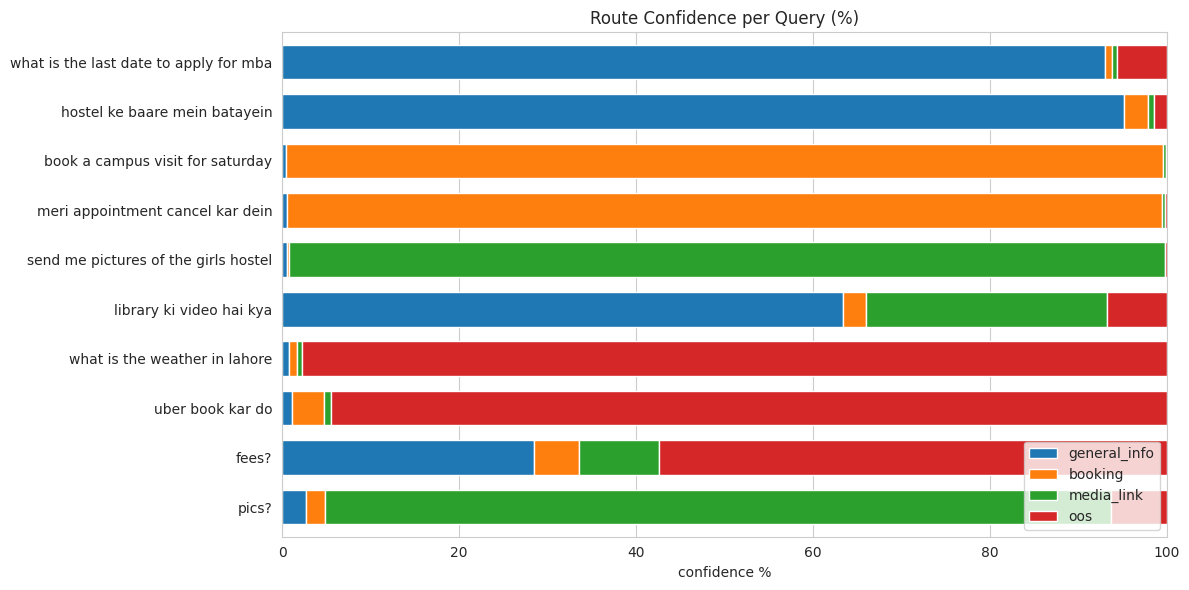

In [29]:
router_model = B_TRAINER.model.eval()


def route_probs(queries):
    enc = tokenizer(queries, return_tensors="pt", padding=True, truncation=True,
                    max_length=MAX_LEN).to(router_model.device)
    with torch.no_grad():
        logits = router_model(**enc).logits.float().cpu().numpy()
    return softmax(logits / TEMPERATURE, axis=1)


def route(query):
    probs = route_probs([query])[0]
    order = np.argsort(-probs)
    return {
        "query": query,
        "route": ID2LABEL[int(order[0])],
        "confidence": round(float(probs[order[0]]) * 100, 2),
        "scores": {ID2LABEL[int(i)]: round(float(probs[i]) * 100, 2) for i in order},
    }


def route_table(queries):
    probs = route_probs(queries) * 100
    table = pd.DataFrame(probs, columns=LABEL_NAMES, index=queries).round(2)
    table.insert(0, "route", table[LABEL_NAMES].idxmax(axis=1))
    table.insert(1, "confidence", table[LABEL_NAMES].max(axis=1))
    return table


print(json.dumps(route("bs computer science ki fee kitni hai"), indent=2))

demo_queries = [
    "what is the last date to apply for mba",
    "hostel ke baare mein batayein",
    "book a campus visit for saturday",
    "meri appointment cancel kar dein",
    "send me pictures of the girls hostel",
    "library ki video hai kya",
    "what is the weather in lahore",
    "uber book kar do",
    "fees?",
    "pics?",
]

scores = route_table(demo_queries)
print(scores.to_string())

scores[LABEL_NAMES].iloc[::-1].plot(kind="barh", stacked=True, figsize=(12, 6), width=0.7)
plt.title("Route Confidence per Query (%)")
plt.xlabel("confidence %")
plt.xlim(0, 100)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [30]:
REVIEW_BELOW = 70.0


def route_table(queries):
    probs = route_probs(queries).astype(np.float64) * 100
    table = pd.DataFrame(probs, columns=LABEL_NAMES, index=queries).round(2)
    table.insert(0, "route", table[LABEL_NAMES].idxmax(axis=1))
    table.insert(1, "confidence", table[LABEL_NAMES].max(axis=1))
    table.insert(2, "needs_review", table["confidence"] < REVIEW_BELOW)
    return table


scores = route_table(demo_queries)
print(scores.to_string())

                                               route  confidence  needs_review  general_info  booking  media_link    oos
what is the last date to apply for mba  general_info       93.04         False         93.04     0.71        0.57   5.68
hostel ke baare mein batayein           general_info       95.20         False         95.20     2.73        0.65   1.42
book a campus visit for saturday             booking       99.13         False          0.42    99.13        0.35   0.10
meri appointment cancel kar dein             booking       98.86         False          0.59    98.86        0.35   0.20
send me pictures of the girls hostel      media_link       98.98         False          0.52     0.30       98.98   0.20
library ki video hai kya                general_info       63.36          True         63.36     2.68       27.17   6.80
what is the weather in lahore                    oos       97.78         False          0.82     0.92        0.48  97.78
uber book kar do                

## Step 9 | Save Model

Model B is saved with its tokenizer and a router config file. The config stores the labels, temperature, review threshold, max length, system prompt and real-world eval scores, so the router can be loaded and used anywhere with the same settings. The saved model is then reloaded and tested to confirm it gives the same result.

In [31]:
B_TRAINER.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

router_config = {
    "labels": LABEL_NAMES,
    "temperature": TEMPERATURE,
    "review_below": REVIEW_BELOW,
    "max_len": MAX_LEN,
    "base_model": MODEL_NAME,
    "system_prompt": SYSTEM_PROMPT,
    "real_eval": {k: round(float(v), 4) for k, v in summarize(y_real, real_pred["Model B"]).items()},
}
with open(os.path.join(OUTPUT_DIR, "router_config.json"), "w") as f:
    json.dump(router_config, f, indent=2)

print("Saved to:", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))
print()

loaded_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
loaded_model = AutoModelForSequenceClassification.from_pretrained(OUTPUT_DIR).to(router_model.device).eval()
with open(os.path.join(OUTPUT_DIR, "router_config.json")) as f:
    loaded_config = json.load(f)

query = "hostel ki pictures bhejo"
enc = loaded_tokenizer([query], return_tensors="pt", truncation=True,
                       max_length=loaded_config["max_len"]).to(loaded_model.device)
with torch.no_grad():
    probs = softmax(loaded_model(**enc).logits.float().cpu().numpy()[0] / loaded_config["temperature"]) * 100

print("Reload check:", query)
for label, p in sorted(zip(loaded_config["labels"], probs), key=lambda x: -x[1]):
    print(f"  {label:<13} {p:6.2f}%")
print("Same as in-memory model:", route(query)["route"] == loaded_config["labels"][int(probs.argmax())])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /kaggle/working/university_router
['config.json', 'model.safetensors', 'router_config.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']



Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Reload check: hostel ki pictures bhejo
  media_link     99.06%
  general_info    0.47%
  booking         0.36%
  oos             0.11%
Same as in-memory model: True


## Conclusion

- Built a 4-route intent router (general_info, booking, media_link, oos) for a university assistant with confidence scores per route.
- A group-wise split exposed that template test scores hide real weaknesses: 0.918 on template test versus 0.525 on natural queries.
- Error analysis found shortcut learning (Roman Urdu meant booking) and missing topics. Fixing the data raised real-world accuracy from 0.525 to 0.700.
- Low-confidence predictions are flagged for review, and in testing the flag caught the wrong predictions.

## Limitations and Next Steps

- 80% real-world accuracy is not yet production ready. The target is around 90%.
- Training data is synthetic. Real user queries from chat logs are the most valuable next addition.
- LLM-generated paraphrases from the system prompt can add natural variety at scale.
- A larger frozen eval set (200 to 400 queries) is needed. The current set has only 80, and it was used for analysis, so it is no longer fully unseen.
- Low-confidence queries can be sent to an LLM fallback or answered with a clarification question.
- Logging predictions in production and retraining on corrected queries will keep improving the router.

### Step 10.1 | Detailed Model Card

The model card is the README of the Hugging Face repo. It explains what the router does, how to use it, how it was trained, how it performs and where it fails. Only the README is updated; the model files stay the same.

In [37]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
api = HfApi(token=HF_TOKEN)
REPO_ID = f"{api.whoami()['name']}/university-intent-router"
print(REPO_ID, "| exists:", api.repo_exists(REPO_ID))

Nasir6/university-intent-router | exists: False


In [39]:
api.create_repo(REPO_ID, private=True, exist_ok=True)
api.upload_folder(
    folder_path=OUTPUT_DIR,
    repo_id=REPO_ID,
    ignore_patterns=["training_args.bin", "README.md"],
    commit_message="Model B: improved data, real-world macro F1 0.70",
)

print("Uploaded to:", f"https://huggingface.co/{REPO_ID}")
print(sorted(api.list_repo_files(REPO_ID)))

hub_tokenizer = AutoTokenizer.from_pretrained(REPO_ID, token=HF_TOKEN)
hub_model = AutoModelForSequenceClassification.from_pretrained(REPO_ID, token=HF_TOKEN).eval()
enc = hub_tokenizer(["book a campus visit for saturday"], return_tensors="pt")
with torch.no_grad():
    hub_probs = softmax(hub_model(**enc).logits.float().numpy()[0]) * 100
print("Hub check:", dict(zip(LABEL_NAMES, hub_probs.round(2))))

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Uploaded to: https://huggingface.co/Nasir6/university-intent-router
['.gitattributes', 'config.json', 'model.safetensors', 'router_config.json', 'tokenizer.json', 'tokenizer_config.json']


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/598M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Hub check: {'general_info': np.float32(0.0), 'booking': np.float32(100.0), 'media_link': np.float32(0.0), 'oos': np.float32(0.0)}


In [40]:
FENCE = "`" * 3


def md_table(frame, index_name=""):
    cols = [index_name] + list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in frame.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [str(v) for v in row.values]) + " |")
    return "\n".join(lines)


real_table = pd.concat([overall, per_class]).round(3)
data_table = pd.crosstab(df_v2["label"], df_v2["split"])[["train", "validation", "test"]].loc[LABEL_NAMES]
source_table = pd.crosstab(df_v2["label"], df_v2["source"]).loc[LABEL_NAMES]
best_b = epoch_log_b["eval_validation_loss"].idxmin()
best_b_loss = epoch_log_b.loc[best_b, "eval_validation_loss"]

usage_code = f"""import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

repo = "{REPO_ID}"
tokenizer = AutoTokenizer.from_pretrained(repo)
model = AutoModelForSequenceClassification.from_pretrained(repo).eval()

query = "hostel ki pictures bhejo"
enc = tokenizer(query, return_tensors="pt", truncation=True, max_length={MAX_LEN})
with torch.no_grad():
    probs = torch.softmax(model(**enc).logits, dim=-1)[0] * 100

scores = sorted(((model.config.id2label[i], round(p.item(), 2)) for i, p in enumerate(probs)), key=lambda x: -x[1])
route, confidence = scores[0]
needs_review = confidence < {REVIEW_BELOW}
print(route, confidence, needs_review, scores)"""

usage_output = "media_link 99.06 False [('media_link', 99.06), ('general_info', 0.47), ('booking', 0.36), ('oos', 0.11)]"

model_card = f"""---
language:
- en
- ur
library_name: transformers
pipeline_tag: text-classification
base_model: {MODEL_NAME}
tags:
- intent-classification
- routing
- university
- roman-urdu
---

# University Intent Router

A ModernBERT-base classifier that routes queries for a university assistant into one of four routes and returns a confidence score for every route. It understands English and Roman Urdu.

## Routes

| Label | Meaning | Example |
|---|---|---|
| general_info | Fees, admissions, programs, eligibility, scholarships, facilities, timings, location | bs cs ki fee kitni hai |
| booking | Book, reschedule or cancel a campus visit, counselor meeting, test slot or appointment | book a campus visit for saturday |
| media_link | Requests for university images, photos or videos | hostel ki pictures bhejo |
| oos | Anything outside these three routes | what is the weather in lahore |

## How to Use

{FENCE}python
{usage_code}
{FENCE}

Output:

{FENCE}
{usage_output}
{FENCE}

**Recommended rule:** if the top confidence is below {REVIEW_BELOW}%, do not route blindly. Ask the user a clarification question or send the query to an LLM fallback. In testing, this flag caught the wrong predictions while leaving correct ones untouched.

## Training Data

There was no public dataset for these routes, so the data was built from a system prompt that defines each route:

- **Templates with slots** (program, facility, topic, day, place) generate natural queries in English and Roman Urdu
- **Seed examples** written by hand for each route
- **Contrast pairs**: the same object appears in different routes (hostel info vs hostel visit booking vs hostel pictures), so the model learns intent instead of keywords
- **Hard negatives**: oos queries that look like routes, such as "uber book kar do" or "dubai ki ticket book karo"
- **CLINC OOS**: out-of-scope queries and queries from unrelated CLINC intents form the oos class
- **Typo copies**: about 30% of rows get realistic keyboard typos

Rows per source:

{md_table(source_table, "label")}

The split is done by template group, not by row, so the validation and test sets contain sentence patterns the model never saw during training.

{md_table(data_table, "label")}

## Training Procedure

| Setting | Value |
|---|---|
| Base model | {MODEL_NAME} |
| Loss | Cross-entropy |
| Optimizer | AdamW |
| Learning rate | {args_b.learning_rate} with warmup and linear decay |
| Weight decay | {args_b.weight_decay} |
| Batch size | {args_b.per_device_train_batch_size} |
| Max length | {MAX_LEN} tokens |
| Max epochs | {int(args_b.num_train_epochs)} with early stopping (patience 2) |
| Best epoch | {best_b:.0f} (lowest validation loss {best_b_loss:.4f}) |
| Precision | fp16 |

## Evaluation

The most important test is a hand-written **real-world eval set** of 80 natural queries (20 per route), never used for training. Four models were compared on it:

- Baseline v1 and Model A: TF-IDF + Logistic Regression and ModernBERT on the original data
- Baseline v2 and Model B: the same two models on the improved data (this repo is Model B)

{md_table(real_table, "metric")}

Key findings:
- Template test scores overestimate real performance. The first model scored 0.918 on template test data but only 0.525 on natural queries.
- Improving the data gave far more than changing the model: +17.5 accuracy points for ModernBERT versus +2.5 from switching TF-IDF to ModernBERT.
- On the improved data, ModernBERT beats the TF-IDF baseline by 10 points.
- Model B's mistakes usually have low confidence, so the review flag can catch them.

## Limitations

- **Not production grade yet**: about 70% accuracy on natural queries. The target for production is around 90%.
- **Synthetic training data**: real user queries are not included yet.
- **Unseen topics fall into oos**: questions about topics missing from training (for example department heads or dress code) are often predicted as oos.
- **Indirect requests**: media or booking requests without clear keywords ("what does it look like inside", "put my name down") can be missed.
- **Small eval set**: 80 queries, so each query changes accuracy by 1.25%. The numbers show a trend, not a final score.
- **Scripts**: trained on English and Roman Urdu only. Urdu script is not supported.

## Intended Use

Routing step in a university chatbot or WhatsApp assistant, followed by a handler per route. Use as a pilot with the review flag on and predictions logged.

Not intended for decisions that affect students without a human or fallback check.

## Next Steps

- Add labeled real user queries from chat logs
- Generate diverse paraphrases with an LLM from the system prompt
- Build a larger frozen eval set of 200 to 400 queries
- Log low-confidence predictions and retrain on corrected labels
"""

with open(os.path.join(OUTPUT_DIR, "README.md"), "w") as f:
    f.write(model_card)

api.upload_file(
    path_or_fileobj=os.path.join(OUTPUT_DIR, "README.md"),
    path_in_repo="README.md",
    repo_id=REPO_ID,
    commit_message="Detailed model card",
)
print("Model card updated:", f"https://huggingface.co/{REPO_ID}")

Model card updated: https://huggingface.co/Nasir6/university-intent-router
